# MINION — relevancia offline: fusión y reranking

Evaluación final de **FiQA-test** y **TREC-COVID-test**, ejecutada en Khipu mediante Slurm. **α = 0,85** fue fijado en FiQA-dev y no se vuelve a ajustar. El corpus y los juicios se conservan tal como fueron publicados; no se entrenan modelos ni se seleccionan configuraciones con test.

## 0. Resumen ejecutivo

- **fiqa:** P@3 fused 0.2515; reranked 0.2310; Δ -0.0206, IC 95 % [-0.0355, -0.0057].
- **trec-covid:** P@3 fused 0.9133; reranked 0.8867; Δ -0.0267, IC 95 % [-0.0933, +0.0333].
- La diferencia compara los mismos candidatos por consulta; solo cambia su orden.
- Los IC usan 10.000 remuestreos pareados de consultas, semilla 42.
- La cobertura de juicios y el resultado condensado se reportan como análisis de sensibilidad.

## 1. Objetivo, protocolo y reproducibilidad

Se pregunta si un cross-encoder mejora la relevancia del top 3 de la fusión híbrida. Una unidad de evaluación es una consulta; las métricas son promedios macro por consulta. El módulo `minion_test.py` acompaña este notebook y contiene los cálculos usados por los jobs. Las etapas costosas tienen caché: al reejecutar se verifican y reutilizan los puntajes ya calculados.

In [1]:
import os, sys, json, time, gc
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path(os.environ.get('MINION_ROOT', str(Path.cwd().parent))).resolve()
OUT = ROOT / 'test_results'
sys.path.insert(0, str(ROOT))
from minion_test import load_dataset, retrieve, rerank, evaluate, sha
alpha = json.loads((OUT / 'alpha_usado.json').read_text())
assert alpha['alpha'] == 0.85 and not alpha['pilot']
assert sha(OUT / 'alpha_usado.json') == sha(ROOT / 'results/alpha.json')
ctx = dict(root=ROOT, out=OUT, pilot=False, alpha=alpha, started=time.monotonic(),
    summary=json.loads((OUT / 'run_summary.json').read_text()))
print('Python:', sys.executable)
print('α:', alpha['alpha'], '| revisión BGE:', alpha['model_revision'])
print('Job de cómputo:', ctx['summary']['job_id'], '| nodo:', ctx['summary']['node'])

Python: /home/usuario/projects/minion_fiqa_alpha/.venv/bin/python
α: 0.85 | revisión BGE: a5beb1e3e68b9ab74eb54cfd186867f64f240e1a
Job de cómputo: 63769 | nodo: ag001


### Configuración congelada y desempates

BM25 usa bm25s/lucene, k1=0,9, b=0,4, stopwords inglesas y PyStemmer english. BGE usa el prefijo especificado solo en consultas, CLS, forward fp16, normalización L2 en float32 y longitud máxima 512. Se busca con `faiss.IndexFlatIP`; los empates se resuelven por ID ascendente, incluso en el corte del top 10. El cross-encoder usa float32 y procesa todos los candidatos de una consulta en un lote. Sus empates conservan el orden fusionado. Los runs TREC usan puntajes monotónicos derivados del rango para conservar ese orden; los puntajes originales se guardan en parquet.

In [2]:
display(pd.DataFrame([alpha['bm25']]))
display(pd.DataFrame([alpha['semantic']]))
print('Normalización:', alpha['normalization'])
print('Desempate:', alpha['document_tie_break'])
print('Reranker:', ctx['summary']['reranker'])

,library,method,k1,b,stopwords,stemmer,top_k
0,bm25s,lucene,0.9,0.4,en,english (PyStemmer),10


,query_prefix,max_length,normalize,index,top_k
0,Represent this sentence for searching relevant...,512,True,faiss.IndexFlatIP,10


Normalización: per-query candidate min-max; constant scores -> 1.0
Desempate: ascending document ID (string)
Reranker: {'specified_alias': 'cross-encoder/ms-marco-MiniLM-L-6-v2', 'canonical_model': 'cross-encoder/ms-marco-MiniLM-L6-v2', 'revision': '233902d25c440f23af6f7d6e94d2946bac0bee0a', 'precision': 'float32'}


## 2. Datos, auditoría y separación desarrollo/prueba

FiQA contiene preguntas y pasajes financieros; TREC-COVID contiene consultas y artículos científicos sobre COVID-19. Se comprueban los conteos de ambos corpus y sus consultas de prueba; los qrels se usan solo para evaluar. No se eliminan textos vacíos ni duplicados: el corpus publicado queda intacto. TREC-COVID incluye dos entradas −1; `trec_eval` las interpreta como sin juicio. La métrica nDCG conserva los grados originales 0, 1 y 2 y el evaluador da ganancia cero a −1. [Convención oficial NIST](https://github.com/usnistgov/trec_eval/blob/main/formats.c).

In [3]:
counts = json.loads((OUT / 'counts.json').read_text())
display(pd.DataFrame(counts).T)
assert counts['fiqa']['corpus'] == 57638 and counts['fiqa']['test_queries'] == 648
assert counts['trec-covid']['corpus'] == 171332 and counts['trec-covid']['test_queries'] == 50

,corpus,test_queries,qrels,positive_qrels,zero_qrels,negative_unjudged_qrels,relevant_queries,empty_titles,empty_texts,duplicate_texts,corpus_sha256,qrels_sha256
fiqa,57638,648,1706,1706,0,0,648,57638,38,39,ff593e4df9933955dc3af83be0c3fa28ac7465f627e08c...,6adc2a640dcdd22bb8b3858f89107adef2a7c3db20a635...
trec-covid,171332,50,66336,24673,41661,2,50,7,42140,0,aded69896598665082316d00df487d22212cc5a8611db0...,10669ab7d526cb04f52079139fd88c3d467a0776441b04...


## 3. FiQA-test: recuperación y fusión

Se lee el corpus completo con texto `title + " " + text`. Solo se usan consultas del split test. La siguiente celda comprueba los datos y muestra un ejemplo real.

In [4]:
state = load_dataset(ctx, 'fiqa')
q = state['qids'][0]
print('Consulta:', q, state['queries'][q])
print('Documento de ejemplo:', state['docs'][0]['_id'], state['texts'][0][:500])

fiqa_data_validated {'corpus': 57638, 'test_queries': 648, 'qrels': 1706, 'positive_qrels': 1706, 'zero_qrels': 0, 'negative_unjudged_qrels': 0, 'relevant_queries': 648, 'empty_titles': 57638, 'empty_texts': 38, 'duplicate_texts': 39, 'corpus_sha256': 'ff593e4df9933955dc3af83be0c3fa28ac7465f627e08c2e53593e734d506517', 'qrels_sha256': '6adc2a640dcdd22bb8b3858f89107adef2a7c3db20a63550dfa7a0f71e379e44'}


Consulta: 10034 Tax implications of holding EWU (or other such UK ETFs) as a US citizen?
Documento de ejemplo: 100  "Only relevant to those with fantasy economy teams. Seriously, Rand's fictional works never translate well into reality because, no matter how hard people try, that ""fiction"" element just can't be ignored.  Test it yourself: Strip John Galt and his followers of everything they have which was created by or within the ""society"" they so revile, drop them in the desert -- and they'll all be dead of exposure and starvation in less than two weeks because they will be naked, without tools and with


### Índice BM25, embeddings y candidatos

Se reutilizan índices y embeddings compatibles. Para cada consulta se unen top 10 BM25 y top 10 denso por ID. Se calculan ambos puntajes de todos los candidatos, incluso cuando un documento llegó por una sola ruta. La normalización min-max se aplica dentro de esta unión; si el vector es constante se asigna 1. La fusión es `(1 − 0,85) × lex_norm + 0,85 × sem_norm`.

In [5]:
candidates = retrieve(ctx, state)
assert candidates.groupby('query_id').size().between(10,20).all()
print('Candidatos:', len(candidates), '| consultas:', candidates.query_id.nunique())
display(candidates.head())

fiqa_candidates_loaded 11665


Candidatos: 11665 | consultas: 648


,query_id,doc_id,corpus_index,lex_raw,sem_raw,lex_norm,sem_norm,lex_rank,sem_rank,fused_score,ce_score
0,10034,180146,8548,10.730046,0.648644,0.952348,0.603932,2,0,0.656194,-1.287480
1,10034,181942,8739,8.783460,0.691382,0.745777,0.828142,0,5,0.815787,-2.219890
2,10034,197478,10335,9.286139,0.685969,0.799121,0.799746,7,9,0.799652,-1.704621
3,10034,295407,20986,1.755770,0.687649,0.000000,0.808561,0,7,0.687277,-7.903689
4,10034,308048,22354,4.164845,0.686757,0.255651,0.803876,0,8,0.721643,-8.330303


### Cross-encoder sobre exactamente los mismos documentos

MiniLM puntúa los pares consulta-documento; no agrega ni elimina candidatos. Se guarda su puntaje original junto con los puntajes de recuperación. El caché permite ejecutar el notebook sin repetir inferencias ya terminadas.

In [6]:
runs = rerank(ctx, state)
assert all(set(runs['fused'][q]) == set(runs['reranked'][q]) for q in state['qids'])
print('Igualdad de candidatos verificada en todas las consultas.')

fiqa_reranked_same_candidates {'queries': 648, 'candidates': 11665}


Igualdad de candidatos verificada en todas las consultas.


### Métricas, contraste independiente y bootstrap pareado

Se calculan P(rel≥1)@3, nDCG@3 y RR(rel≥1)@10 con `ir_measures`. Recall@20 se reporta solo para fused y promedia consultas con al menos un relevante. Un segundo cálculo explícito por consulta debe coincidir con el evaluador. Cada remuestreo usa los mismos IDs de consultas para fused y reranked; se reinicia `default_rng(42)` por dataset.

In [7]:
comparison = evaluate(ctx, state)
display(pd.read_csv(OUT / 'metrics.csv').query("dataset == 'fiqa'"))
display(pd.DataFrame([comparison]))
del state, candidates, runs
gc.collect()

fiqa_metrics_bootstrap_complete {'dataset': 'fiqa', 'n_queries': 648, 'resamples': 10000, 'seed': 42, 'delta_precision_at_3': -0.020576131687242795, 'ci_95_low': -0.035493827160493825, 'ci_95_high': -0.005658436213991769, 'condensed_delta_precision_at_3': 0.0, 'delta_sign_preserved': False}


,dataset,route,n_queries,precision_at_3,ndcg_at_3,mrr_at_10,recall_at_20,recall_queries
4,fiqa,lex,648,0.137860,0.207923,0.298977,NaN,NaN
5,fiqa,sem,648,0.245885,0.366828,0.485649,NaN,NaN
6,fiqa,fused,648,0.251543,0.376924,0.500347,0.530503,648.0
7,fiqa,reranked,648,0.230967,0.340071,0.448184,NaN,NaN


,dataset,n_queries,resamples,seed,delta_precision_at_3,ci_95_low,ci_95_high,condensed_delta_precision_at_3,delta_sign_preserved
0,fiqa,648,10000,42,-0.020576,-0.035494,-0.005658,0.0,False


98

## 3. TREC-COVID-test: recuperación y fusión

Se lee el corpus completo con texto `title + " " + text`. Solo se usan consultas del split test. La siguiente celda comprueba los datos y muestra un ejemplo real.

In [8]:
state = load_dataset(ctx, 'trec-covid')
q = state['qids'][0]
print('Consulta:', q, state['queries'][q])
print('Documento de ejemplo:', state['docs'][0]['_id'], state['texts'][0][:500])

trec-covid_data_validated {'corpus': 171332, 'test_queries': 50, 'qrels': 66336, 'positive_qrels': 24673, 'zero_qrels': 41661, 'negative_unjudged_qrels': 2, 'relevant_queries': 50, 'empty_titles': 7, 'empty_texts': 42140, 'duplicate_texts': 0, 'corpus_sha256': 'aded69896598665082316d00df487d22212cc5a8611db05db34eb40d04ed00d7', 'qrels_sha256': '10669ab7d526cb04f52079139fd88c3d467a0776441b046567f540582798982b'}


Consulta: 1 what is the origin of COVID-19
Documento de ejemplo: 0002xs6a The Father-Daughter Dinner Dance: A Waltz With Ethics and COVID-19 Commentary on "The Father-Daughter Dinner Dance: A Waltz With Ethics and COVID-19" 


### Índice BM25, embeddings y candidatos

Se reutilizan índices y embeddings compatibles. Para cada consulta se unen top 10 BM25 y top 10 denso por ID. Se calculan ambos puntajes de todos los candidatos, incluso cuando un documento llegó por una sola ruta. La normalización min-max se aplica dentro de esta unión; si el vector es constante se asigna 1. La fusión es `(1 − 0,85) × lex_norm + 0,85 × sem_norm`.

In [9]:
candidates = retrieve(ctx, state)
assert candidates.groupby('query_id').size().between(10,20).all()
print('Candidatos:', len(candidates), '| consultas:', candidates.query_id.nunique())
display(candidates.head())

trec-covid_candidates_loaded 930


Candidatos: 930 | consultas: 50


,query_id,doc_id,corpus_index,lex_raw,sem_raw,lex_norm,sem_norm,lex_rank,sem_rank,fused_score,ce_score
0,1,0paafp5j,3303,6.169785,0.697522,0.715009,0.203368,2,0,0.280114,6.546769
1,1,105q161g,4744,3.887908,0.779297,0.118365,0.741538,0,9,0.648062,7.465428
2,1,1ij25a7u,7194,5.774075,0.666620,0.611543,0.000000,5,0,0.091731,4.452649
3,1,4dtk1kyh,20973,4.699215,0.816833,0.330498,0.988567,0,2,0.889857,8.576168
4,1,5d7zien3,25538,5.661628,0.693284,0.582141,0.175475,6,0,0.236475,5.872139


### Cross-encoder sobre exactamente los mismos documentos

MiniLM puntúa los pares consulta-documento; no agrega ni elimina candidatos. Se guarda su puntaje original junto con los puntajes de recuperación. El caché permite ejecutar el notebook sin repetir inferencias ya terminadas.

In [10]:
runs = rerank(ctx, state)
assert all(set(runs['fused'][q]) == set(runs['reranked'][q]) for q in state['qids'])
print('Igualdad de candidatos verificada en todas las consultas.')

trec-covid_reranked_same_candidates {'queries': 50, 'candidates': 930}


Igualdad de candidatos verificada en todas las consultas.


### Métricas, contraste independiente y bootstrap pareado

Se calculan P(rel≥1)@3, nDCG@3 y RR(rel≥1)@10 con `ir_measures`. Recall@20 se reporta solo para fused y promedia consultas con al menos un relevante. Un segundo cálculo explícito por consulta debe coincidir con el evaluador. Cada remuestreo usa los mismos IDs de consultas para fused y reranked; se reinicia `default_rng(42)` por dataset.

In [11]:
comparison = evaluate(ctx, state)
display(pd.read_csv(OUT / 'metrics.csv').query("dataset == 'trec-covid'"))
display(pd.DataFrame([comparison]))
del state, candidates, runs
gc.collect()

trec-covid_metrics_bootstrap_complete {'dataset': 'trec-covid', 'n_queries': 50, 'resamples': 10000, 'seed': 42, 'delta_precision_at_3': -0.026666666666666665, 'ci_95_low': -0.09333333333333334, 'ci_95_high': 0.03333333333333333, 'condensed_delta_precision_at_3': -0.026666666666666665, 'delta_sign_preserved': True}


,dataset,route,n_queries,precision_at_3,ndcg_at_3,mrr_at_10,recall_at_20,recall_queries
4,trec-covid,lex,50,0.700000,0.644693,0.838524,NaN,NaN
5,trec-covid,sem,50,0.873333,0.811229,0.918000,NaN,NaN
6,trec-covid,fused,50,0.913333,0.858882,0.940000,0.033915,50.0
7,trec-covid,reranked,50,0.886667,0.824693,0.914000,NaN,NaN


,dataset,n_queries,resamples,seed,delta_precision_at_3,ci_95_low,ci_95_high,condensed_delta_precision_at_3,delta_sign_preserved
0,trec-covid,50,10000,42,-0.026667,-0.093333,0.033333,-0.026667,True


36

## 4. Resultados visuales

Todas las figuras fueron generadas con matplotlib y guardadas como PNG a 200 dpi. Los colores siguen Okabe–Ito. Los intervalos R1 son marginales; R2 presenta la diferencia pareada.

### R3 alpha fiqa dev

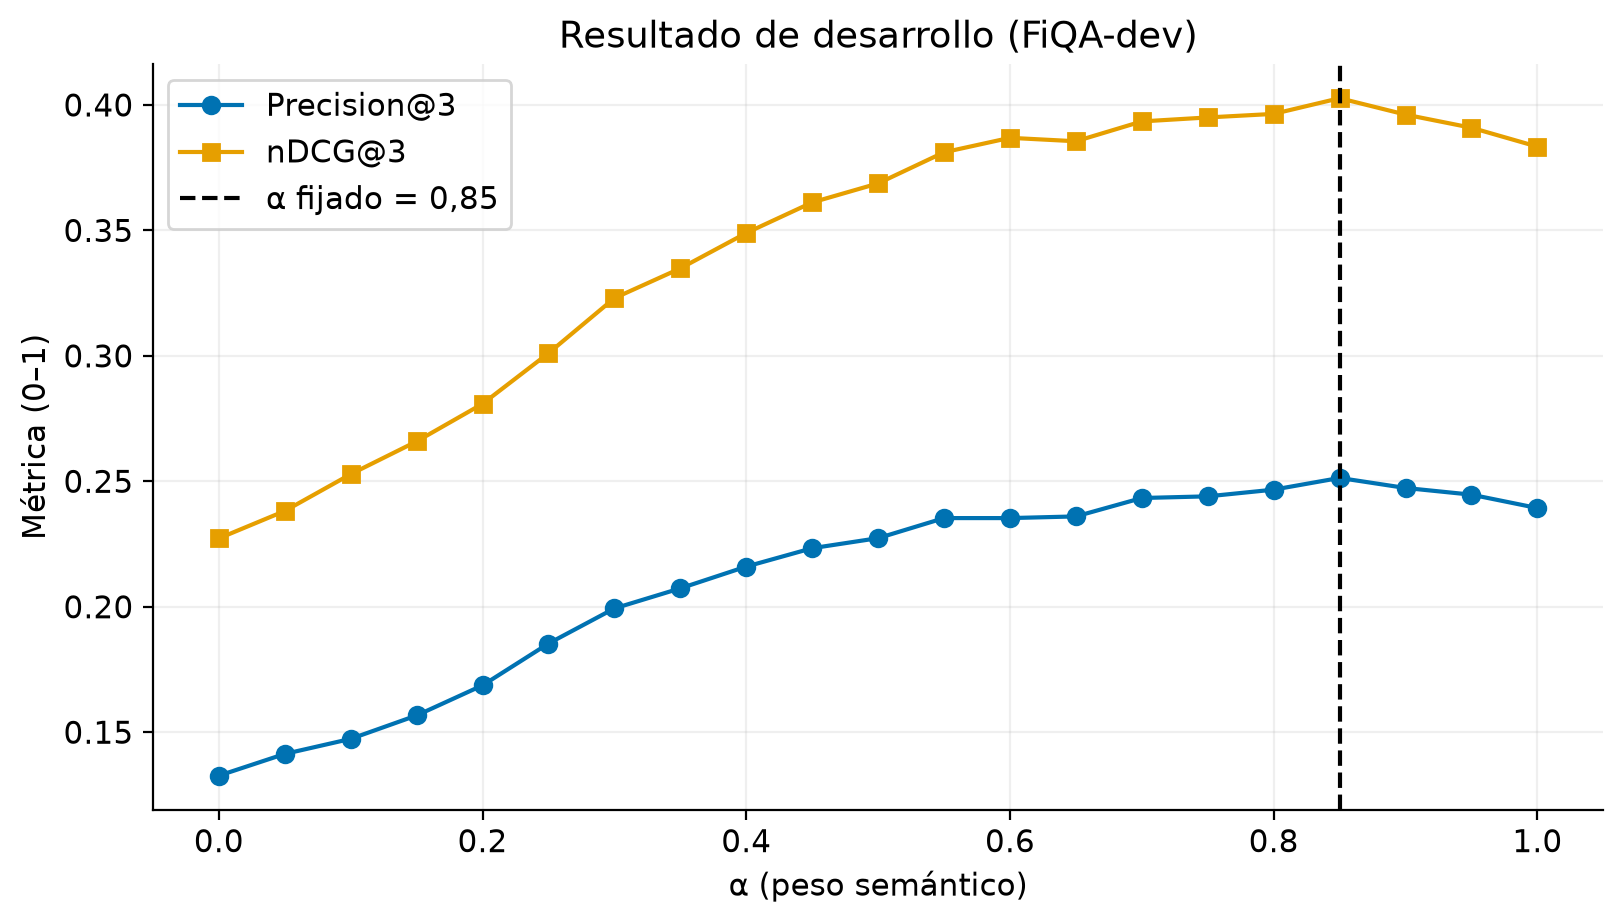

In [12]:
display(Image(filename=str(OUT / 'figs' / 'R3_alpha_fiqa_dev.png')))

La curva proviene del archivo validado de desarrollo: no se recalculó ni se usó test para ajustar α.
El valor fijo 0,85 se aplica sin cambios a FiQA-test y TREC-COVID.

### R1 metricas fiqa

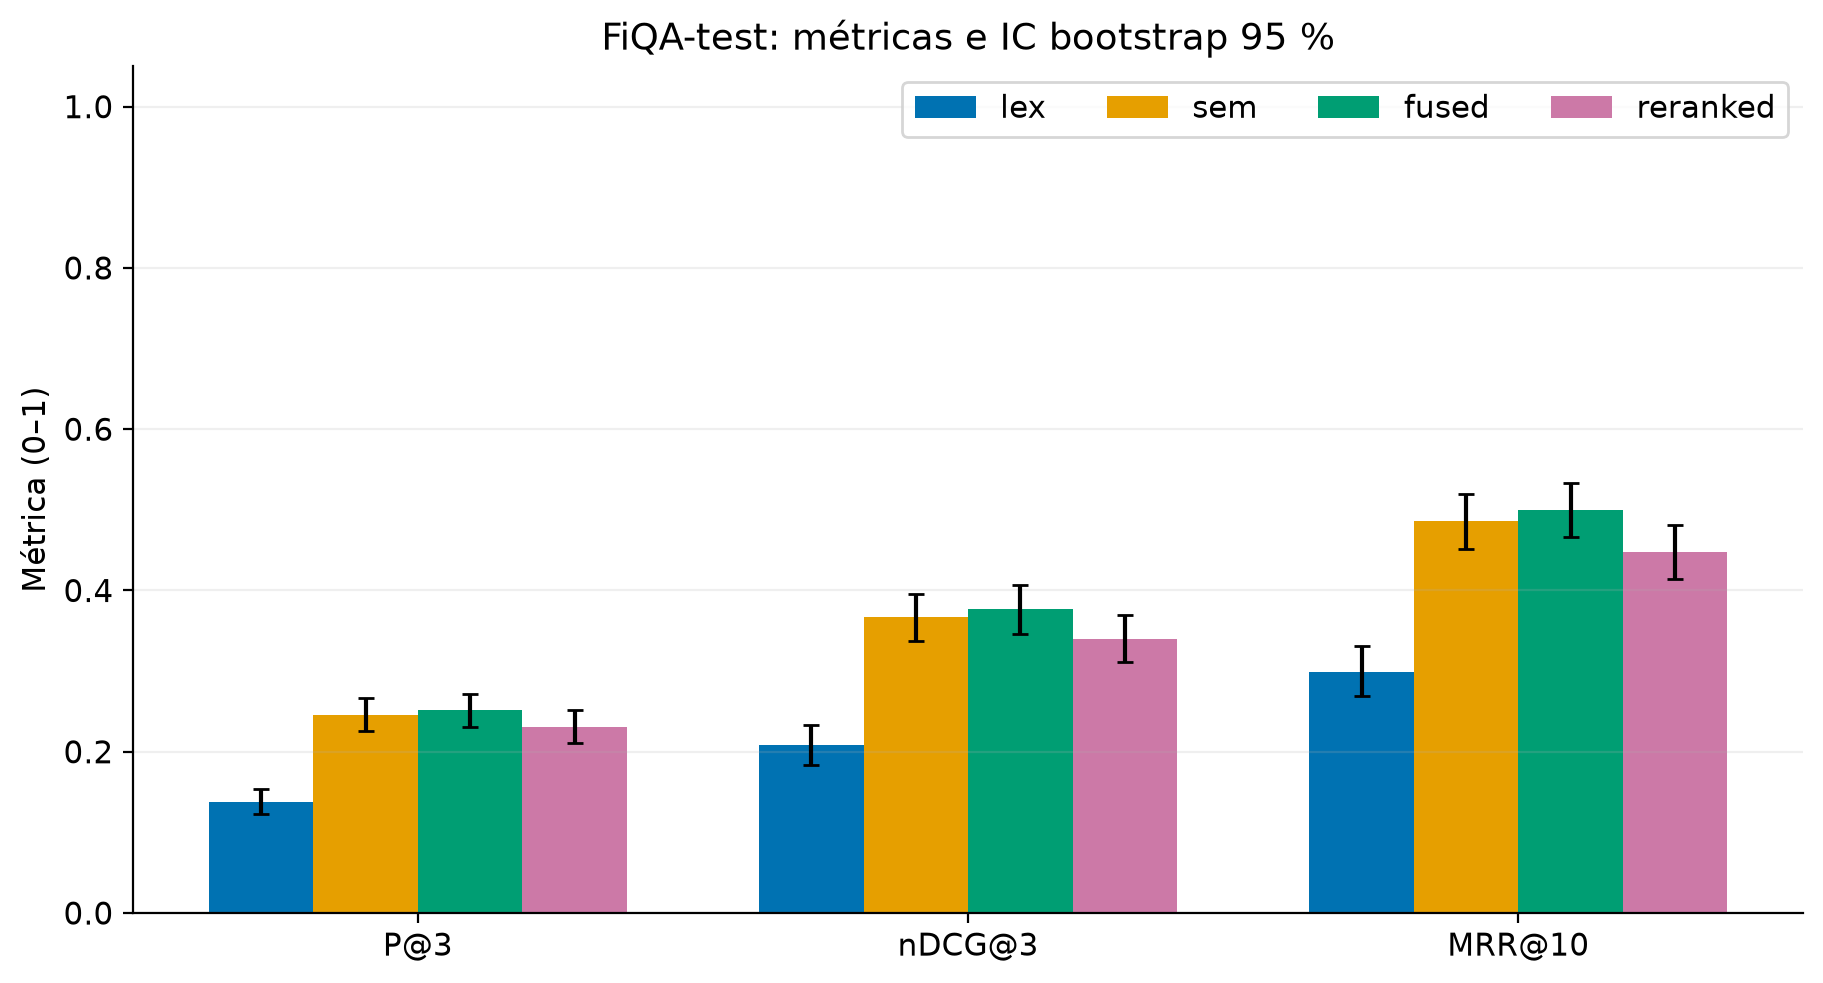

In [13]:
display(Image(filename=str(OUT / 'figs' / 'R1_metricas_fiqa.png')))

P@3 pasa de 0.2515 (fusión) a 0.2310 (reranking).
Las barras muestran IC marginales; la comparación pareada de ΔP@3 está en R2. MRR de lex y sem es complementario.

### R2 bootstrap fiqa

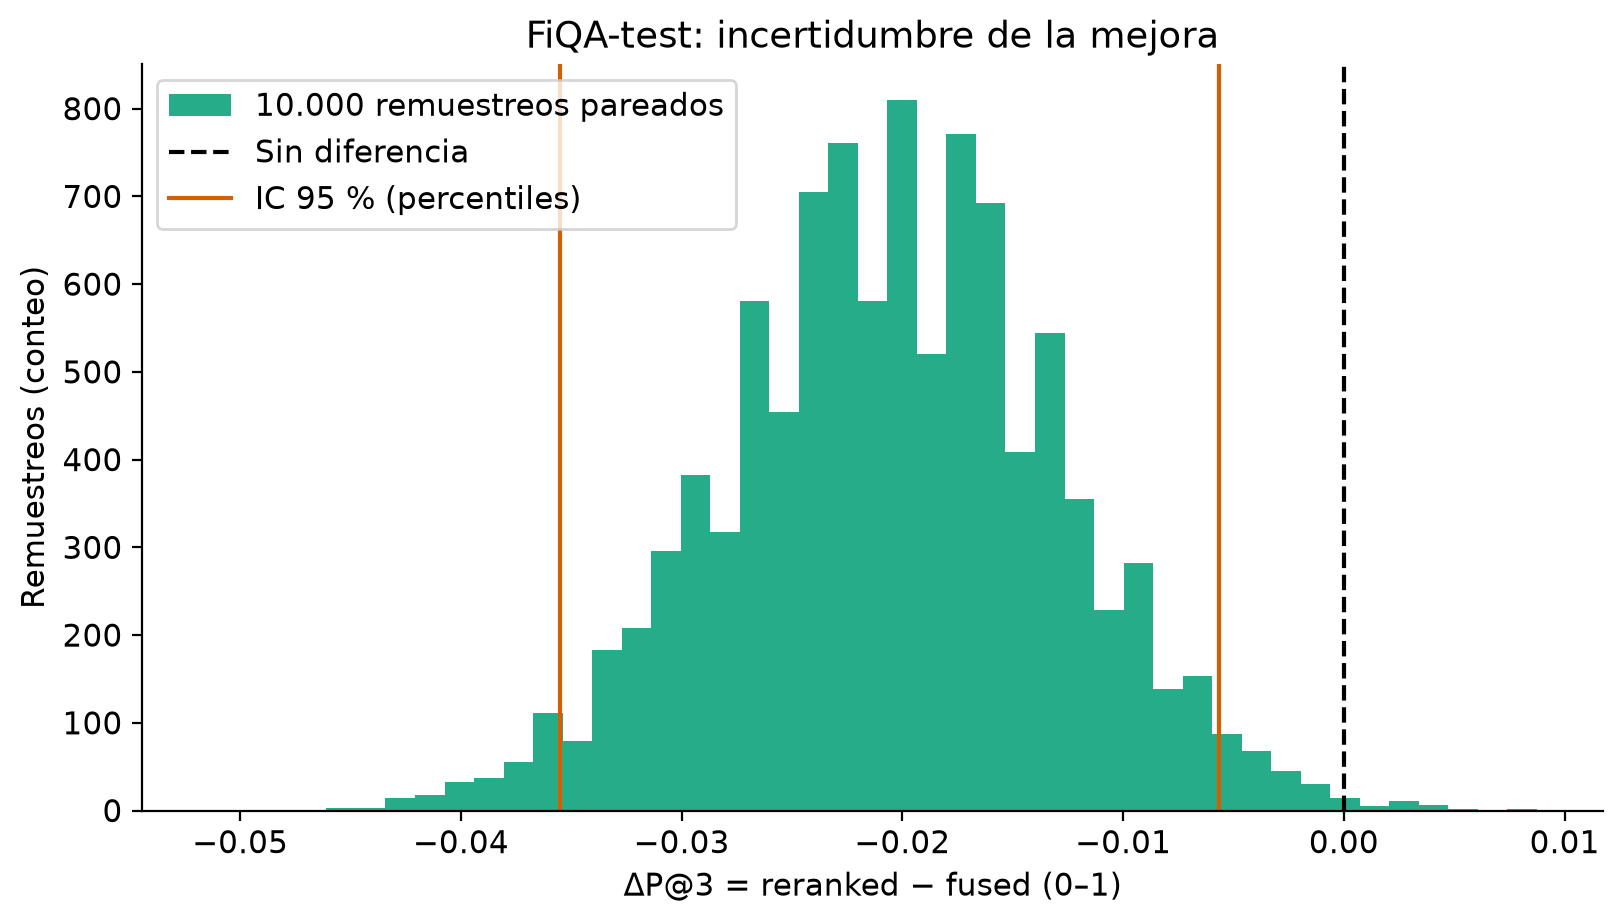

In [14]:
display(Image(filename=str(OUT / 'figs' / 'R2_bootstrap_fiqa.png')))

ΔP@3 = -0.0206; IC 95 % [-0.0355, -0.0057].
El intervalo es negativo; el remuestreo conserva el emparejamiento por consulta.

### R4 matriz transicion fiqa

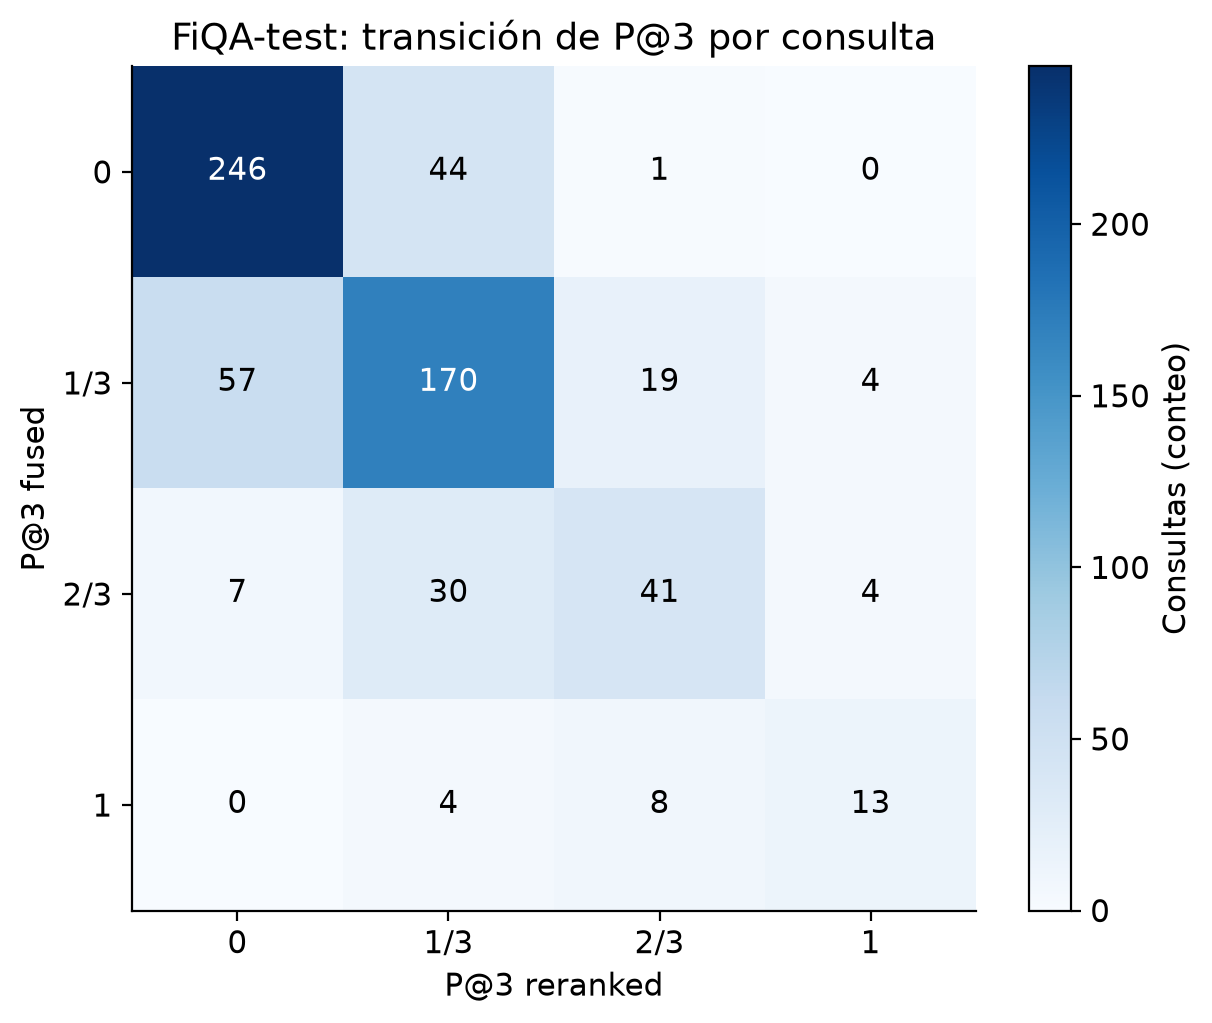

In [15]:
display(Image(filename=str(OUT / 'figs' / 'R4_matriz_transicion_fiqa.png')))

72 consultas mejoran, 470 empatan y 106 empeoran.
Las celdas a la derecha y por encima de la diagonal representan mejoras; la diagonal representa empates.

### R5 gana empata pierde fiqa

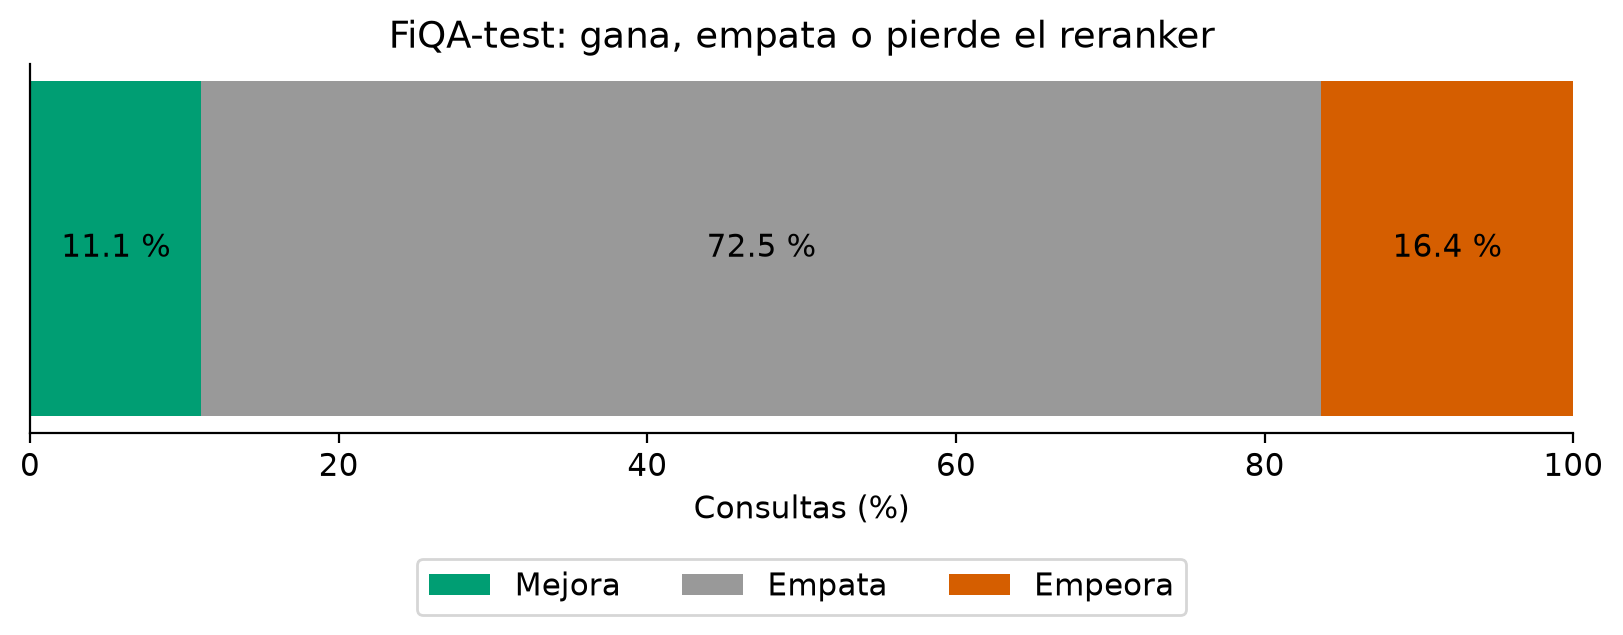

In [16]:
display(Image(filename=str(OUT / 'figs' / 'R5_gana_empata_pierde_fiqa.png')))

El reranker mejora 11.1 %, empata 72.5 % y empeora 16.4 % de las consultas.
El cambio promedio debe interpretarse junto con estas diferencias entre consultas.

### R6 matriz posiciones fiqa

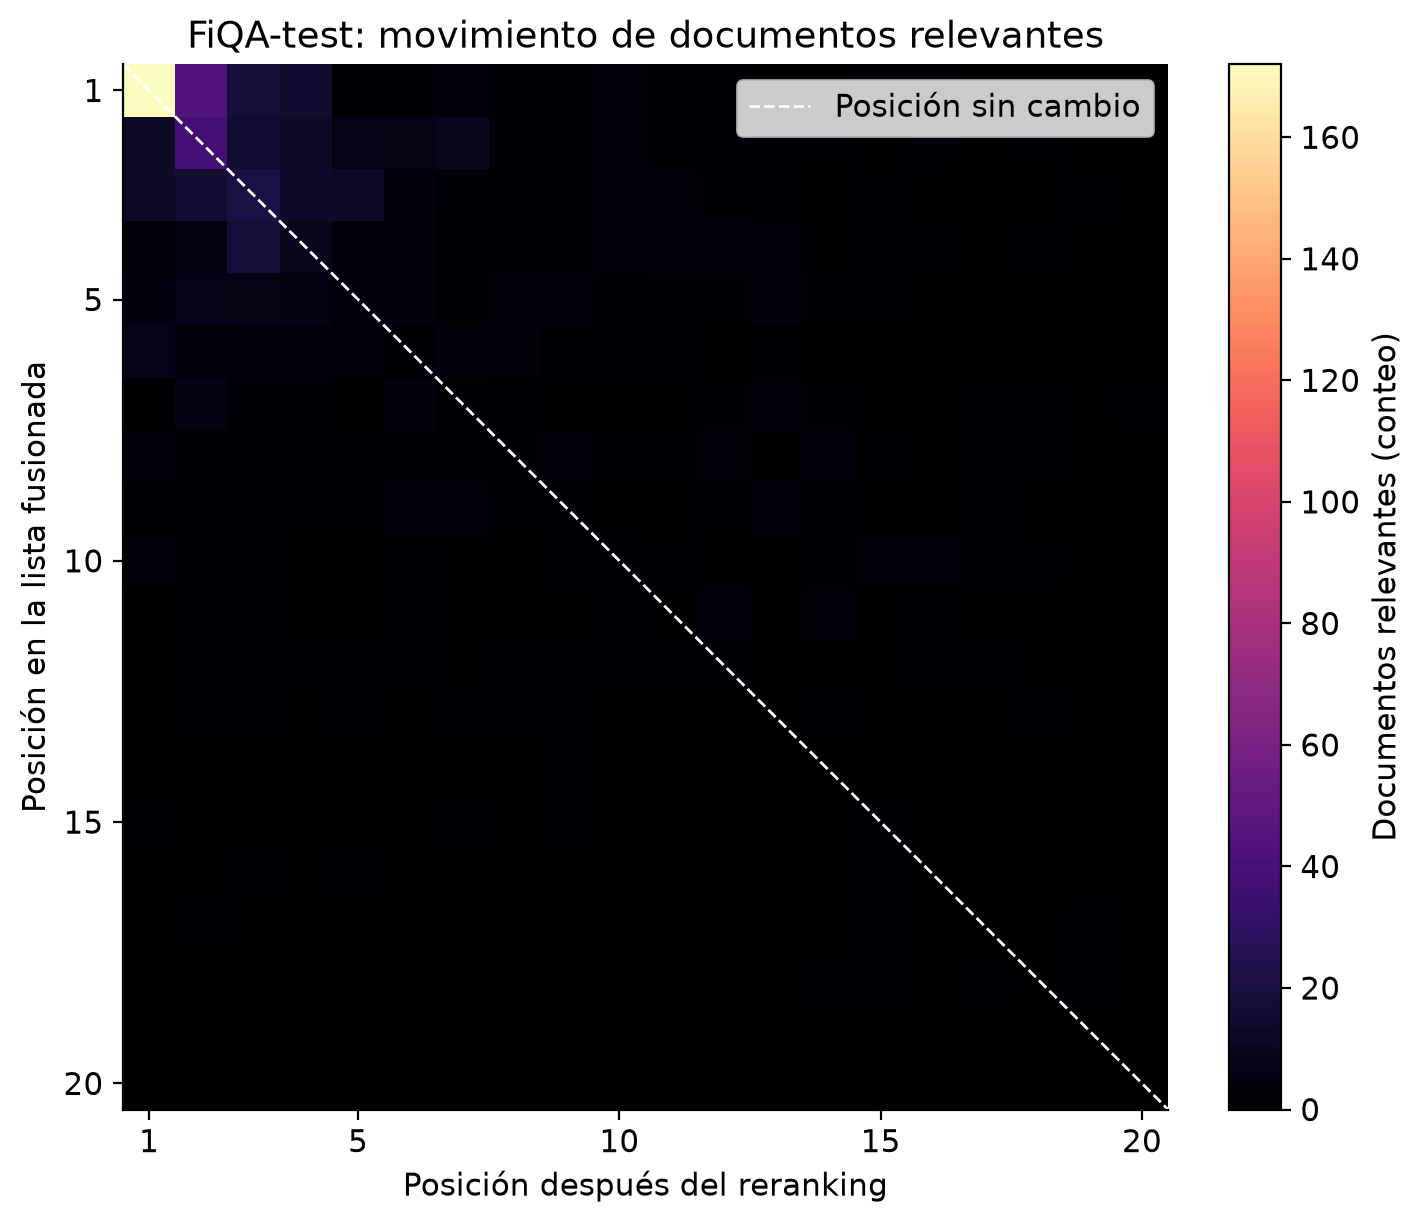

In [17]:
display(Image(filename=str(OUT / 'figs' / 'R6_matriz_posiciones_fiqa.png')))

97 relevantes entran al top 3 desde posiciones inferiores; 137 salen del top 3.
Cada documento es el mismo antes y después: esta figura aísla el efecto de reordenar candidatos.

### R7 origen candidatos fiqa

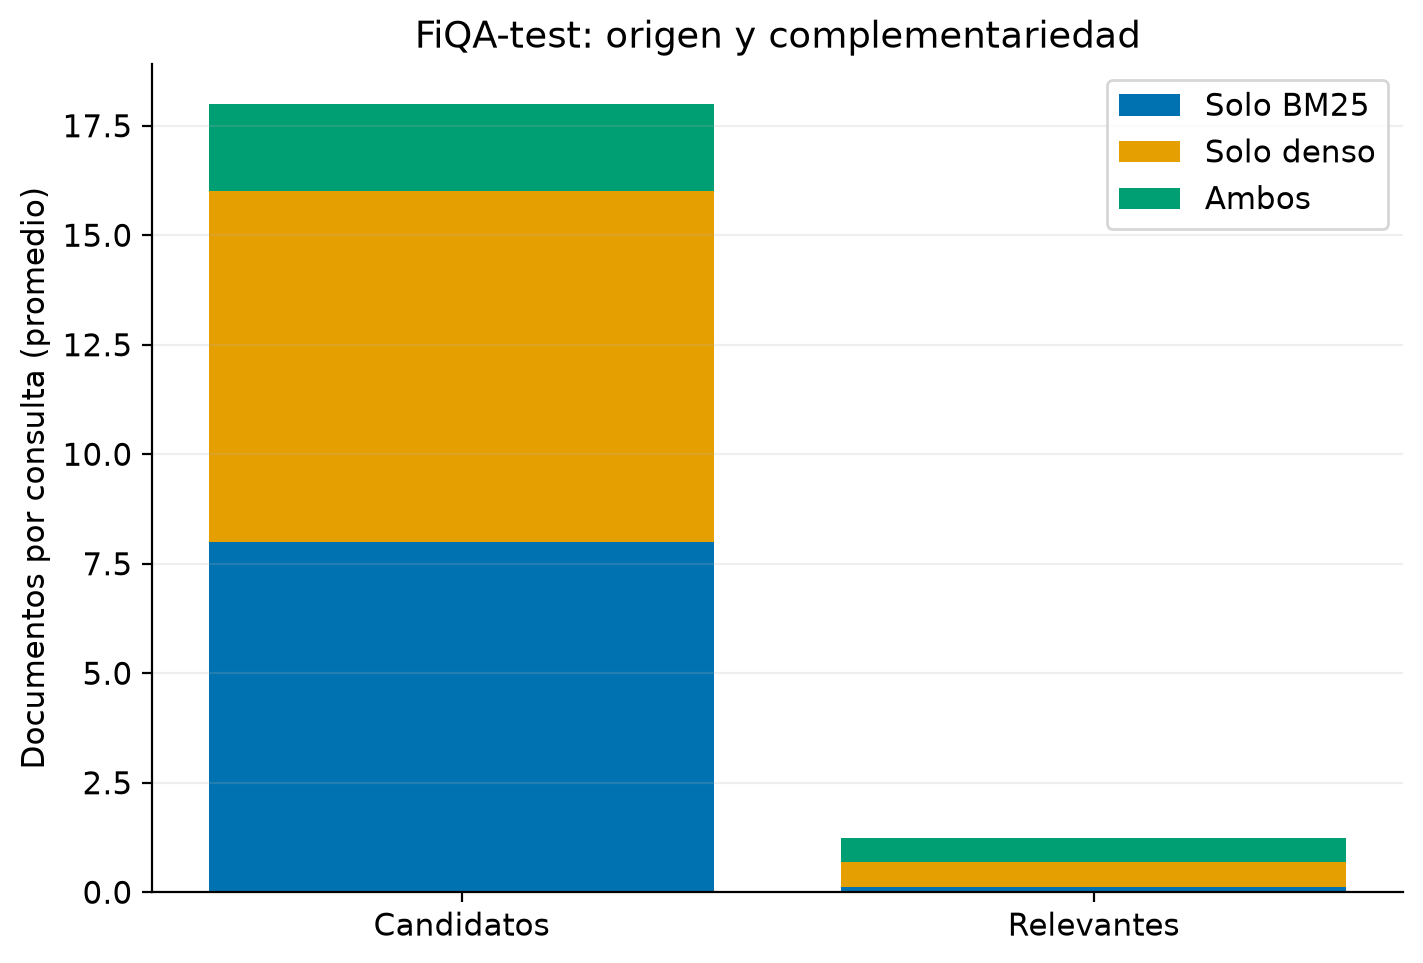

In [18]:
display(Image(filename=str(OUT / 'figs' / 'R7_origen_candidatos_fiqa.png')))

La unión contiene 18.00 candidatos por consulta y 1.23 relevantes juzgados.
Los aportes relevantes exclusivos de BM25 y denso son 0.11 y 0.58 por consulta.

### R8 judged fiqa

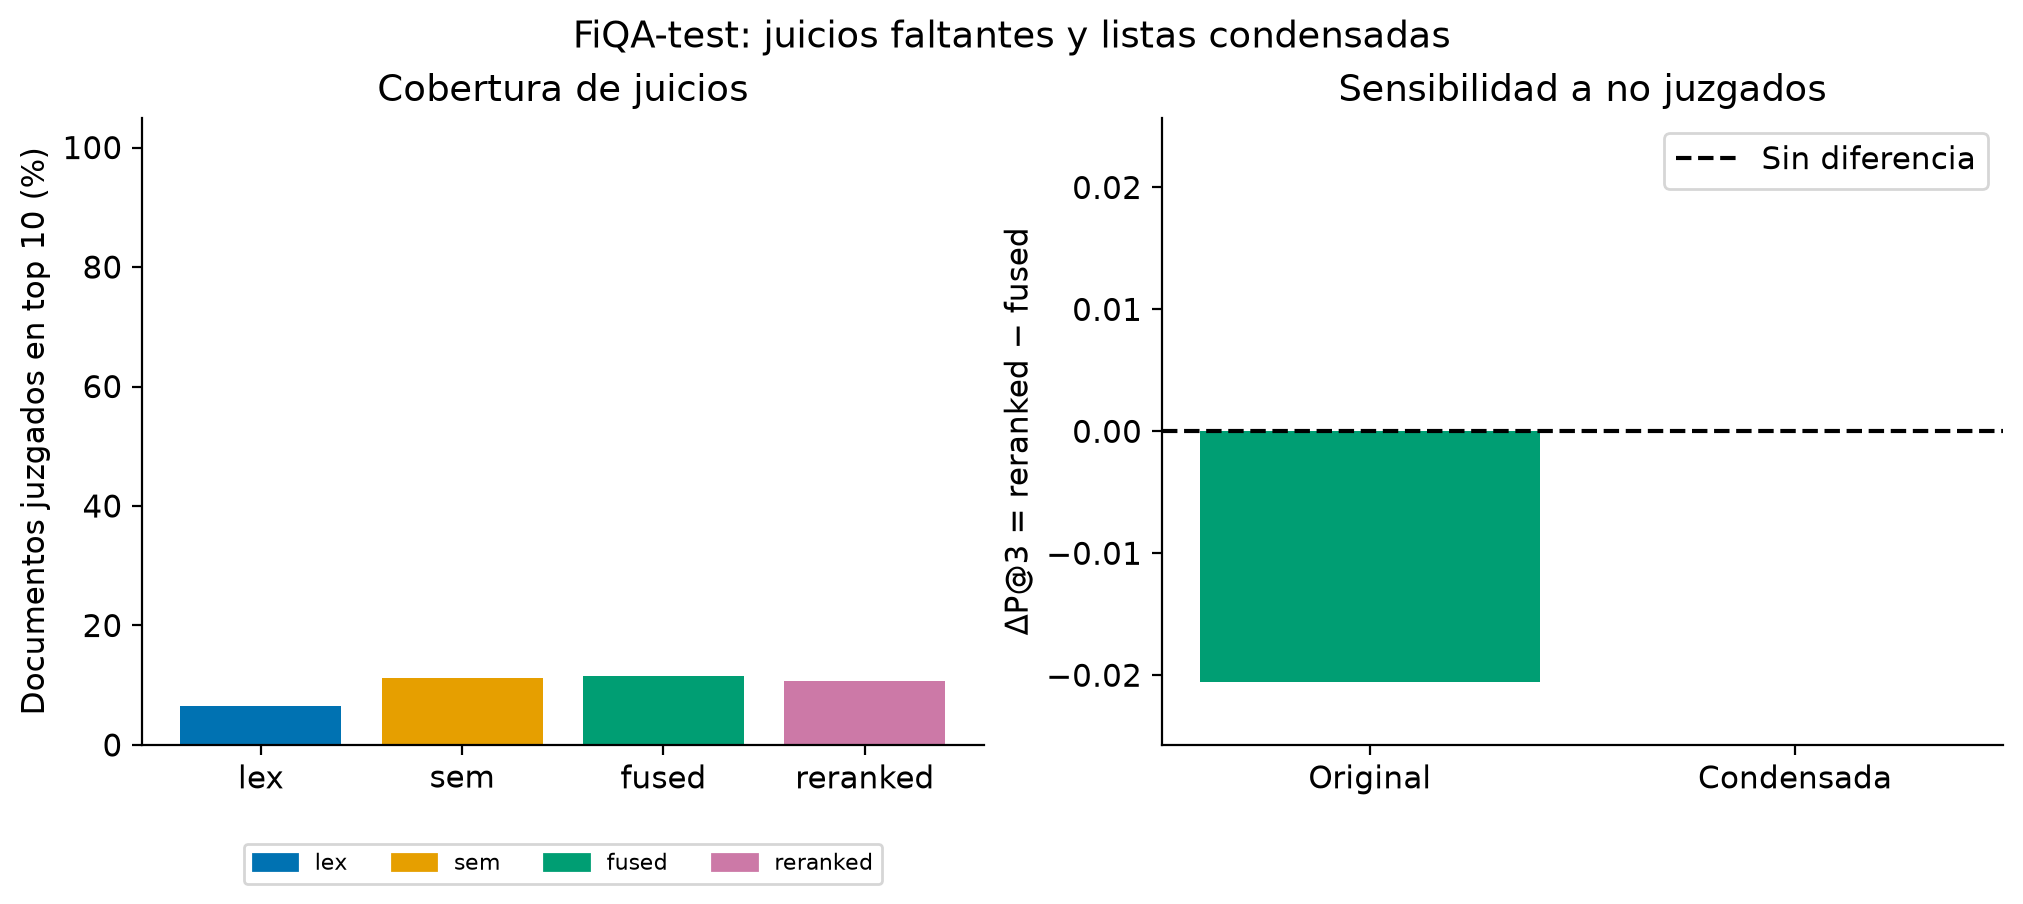

In [19]:
display(Image(filename=str(OUT / 'figs' / 'R8_judged_fiqa.png')))

Judged@10: fusión 11.6 %, reranker 10.6 %. Los grados 0 cuentan como juzgados.
ΔP@3 condensada = +0.0000; cambia el signo respecto de la evaluación original. FiQA solo tiene juicios positivos: el empate de P@3 condensada es estructural al compartir candidatos.

### R1 metricas trec-covid

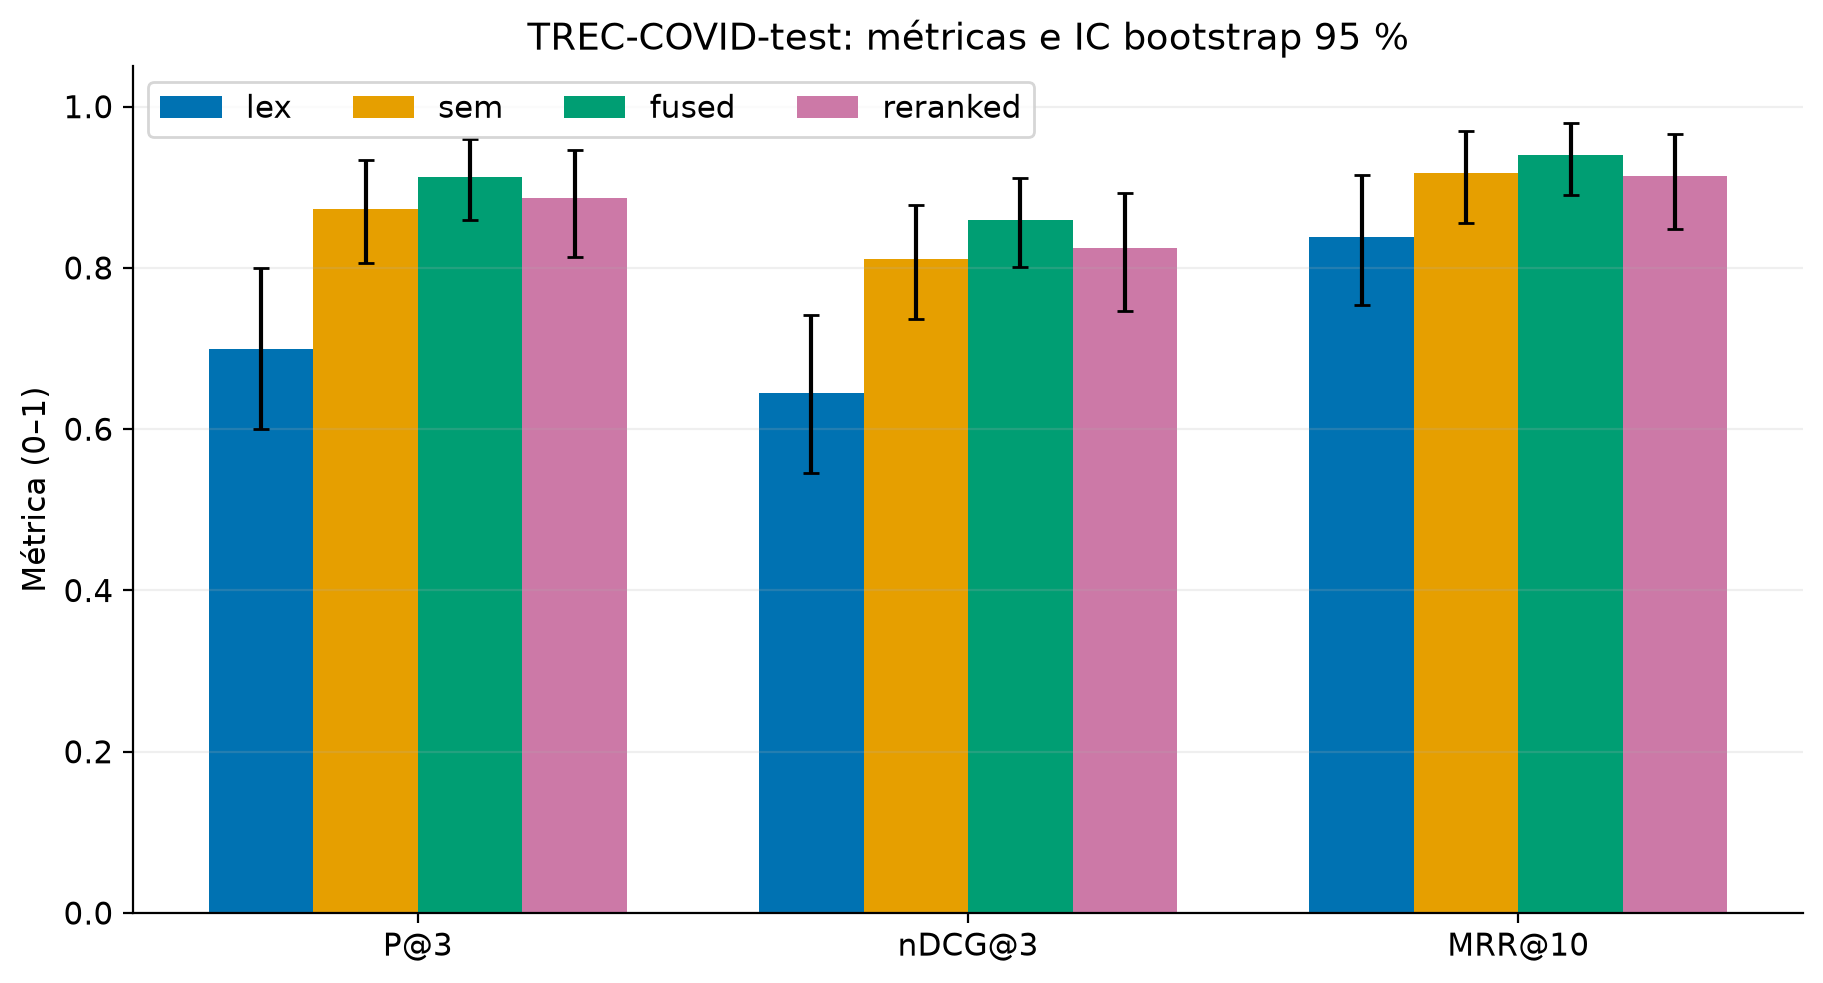

In [20]:
display(Image(filename=str(OUT / 'figs' / 'R1_metricas_trec-covid.png')))

P@3 pasa de 0.9133 (fusión) a 0.8867 (reranking).
Las barras muestran IC marginales; la comparación pareada de ΔP@3 está en R2. MRR de lex y sem es complementario.

### R2 bootstrap trec-covid

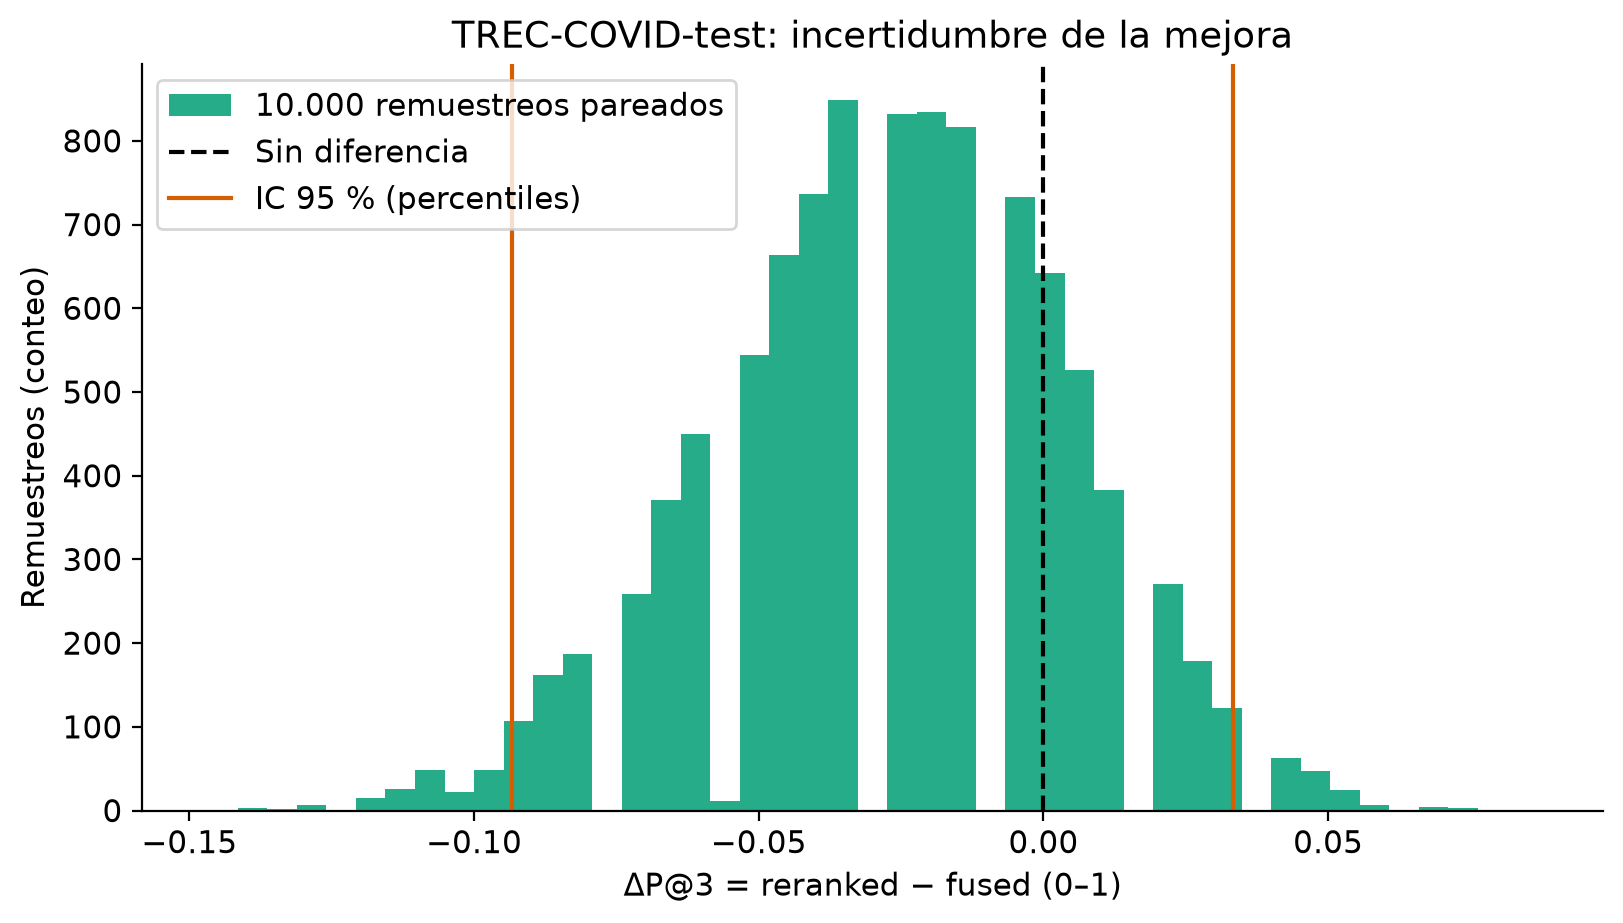

In [21]:
display(Image(filename=str(OUT / 'figs' / 'R2_bootstrap_trec-covid.png')))

ΔP@3 = -0.0267; IC 95 % [-0.0933, +0.0333].
El intervalo es compatible con cero; el remuestreo conserva el emparejamiento por consulta.

### R4 matriz transicion trec-covid

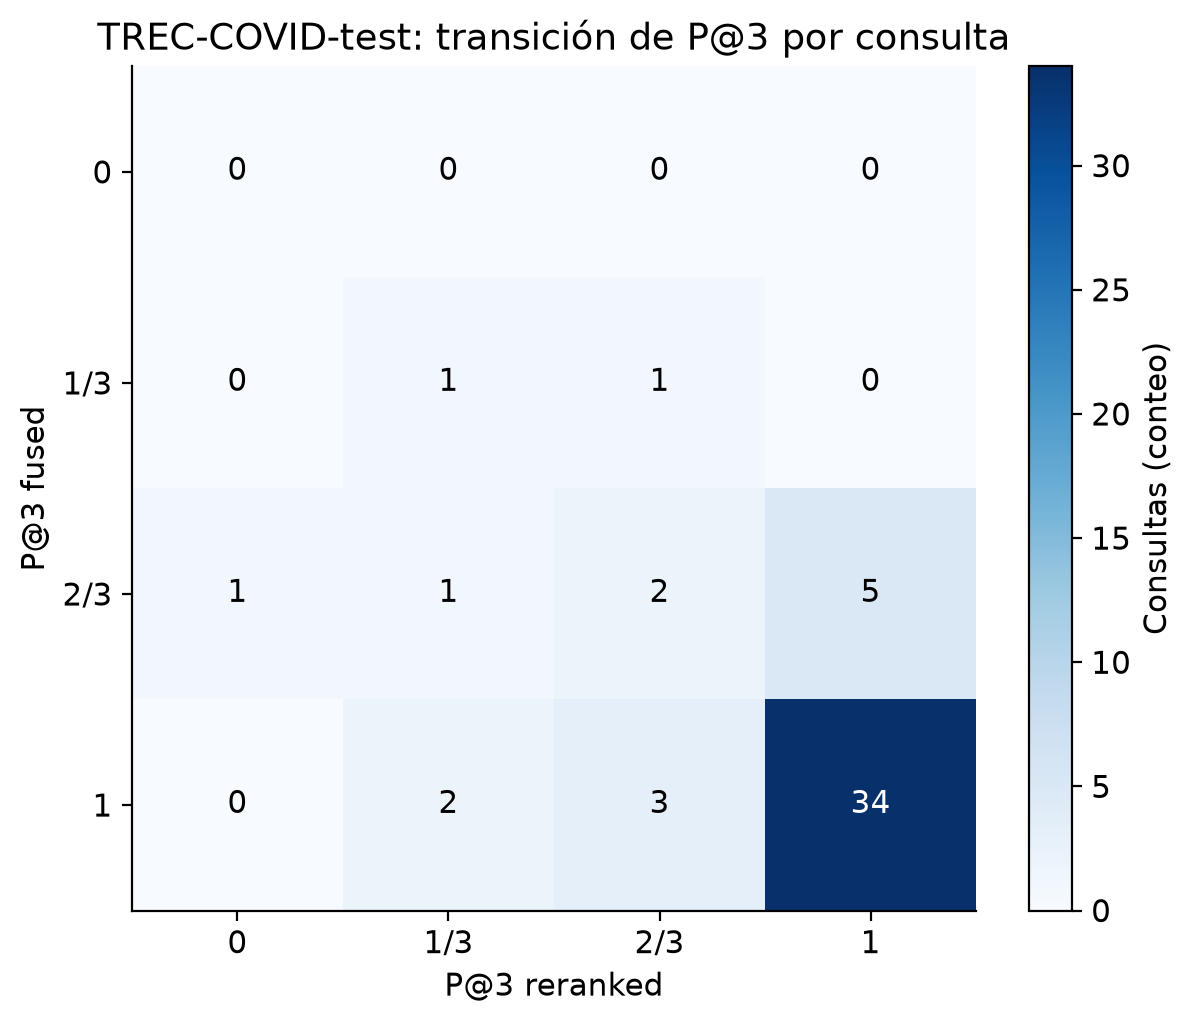

In [22]:
display(Image(filename=str(OUT / 'figs' / 'R4_matriz_transicion_trec-covid.png')))

6 consultas mejoran, 37 empatan y 7 empeoran.
Las celdas a la derecha y por encima de la diagonal representan mejoras; la diagonal representa empates.

### R5 gana empata pierde trec-covid

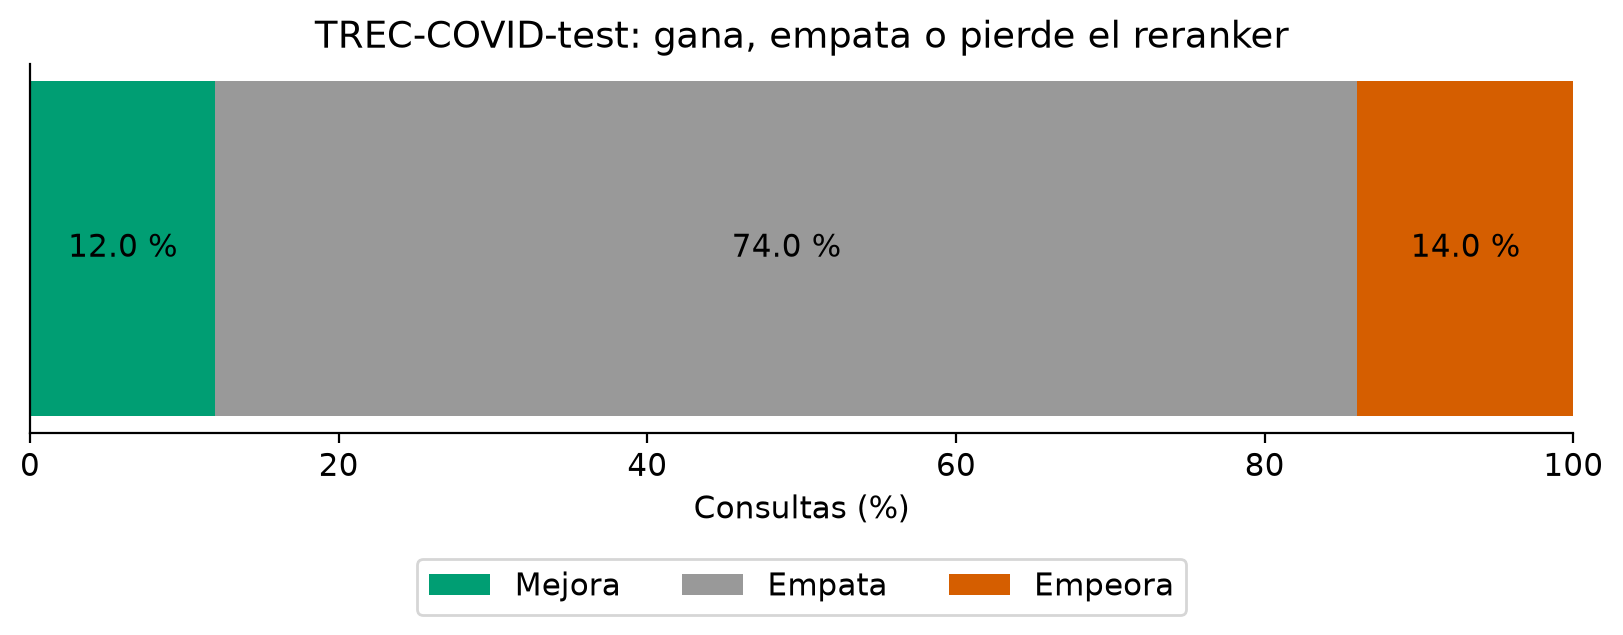

In [23]:
display(Image(filename=str(OUT / 'figs' / 'R5_gana_empata_pierde_trec-covid.png')))

El reranker mejora 12.0 %, empata 74.0 % y empeora 14.0 % de las consultas.
El cambio promedio debe interpretarse junto con estas diferencias entre consultas.

### R6 matriz posiciones trec-covid

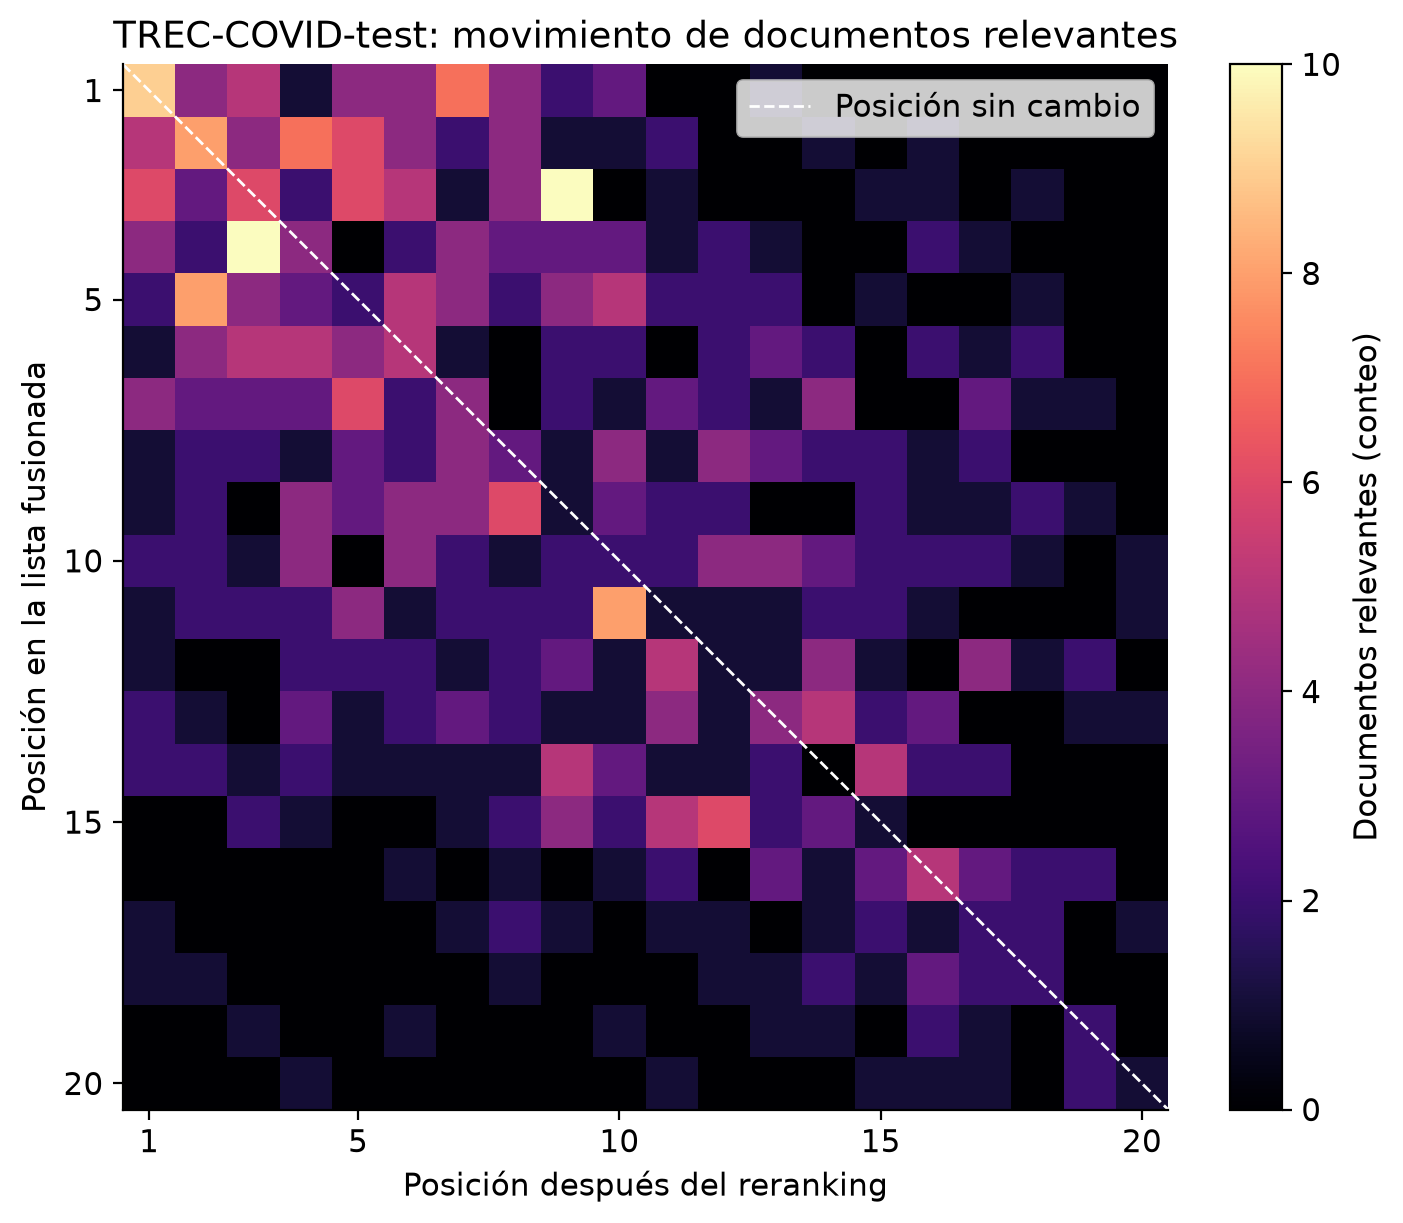

In [24]:
display(Image(filename=str(OUT / 'figs' / 'R6_matriz_posiciones_trec-covid.png')))

83 relevantes entran al top 3 desde posiciones inferiores; 87 salen del top 3.
Cada documento es el mismo antes y después: esta figura aísla el efecto de reordenar candidatos.

### R7 origen candidatos trec-covid

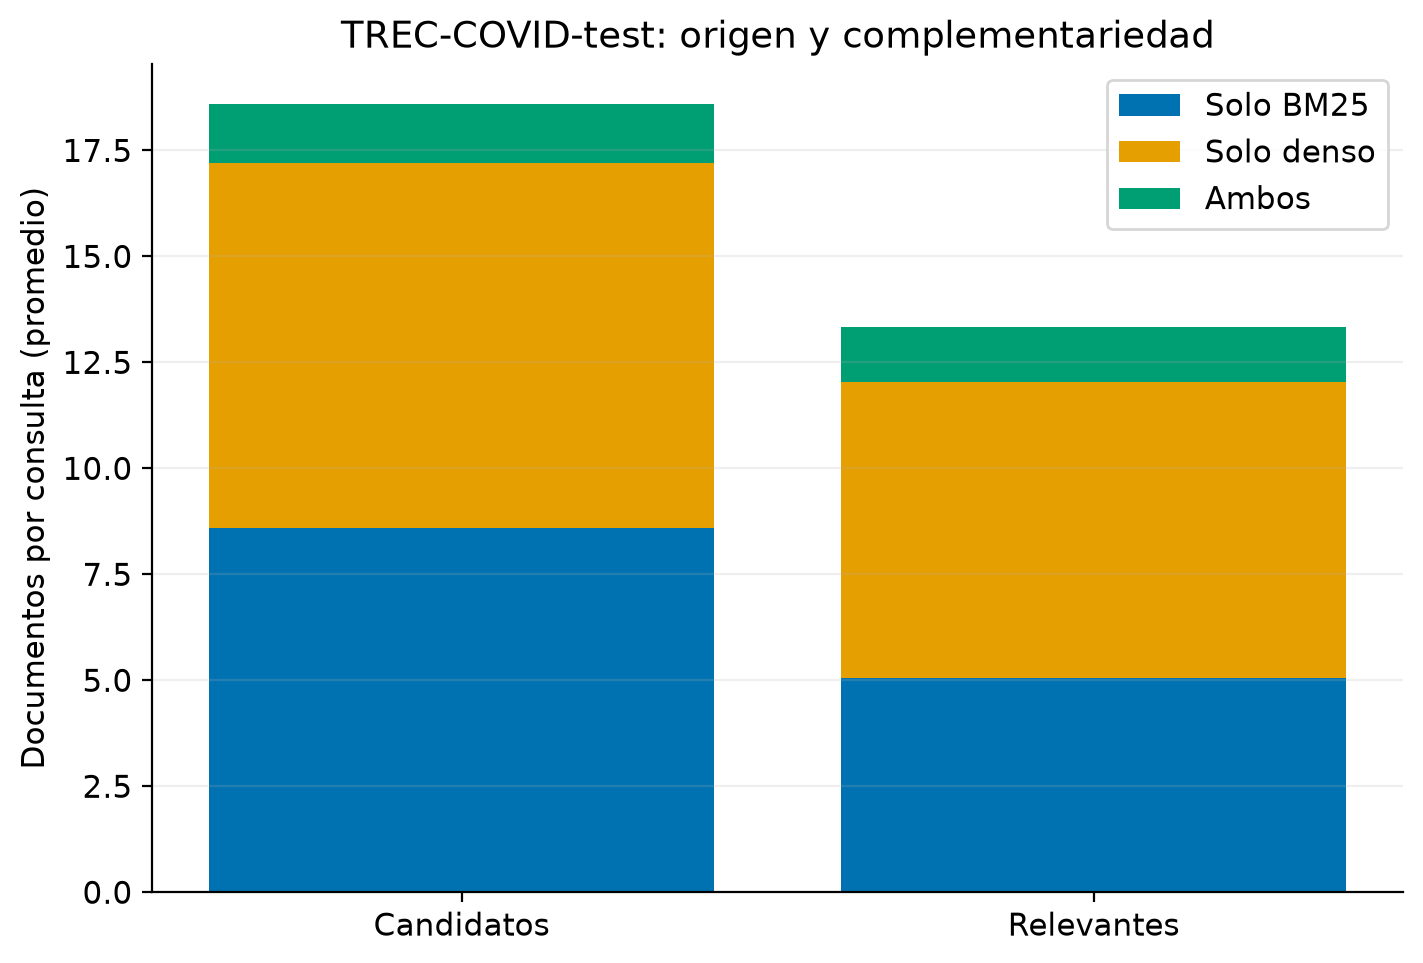

In [25]:
display(Image(filename=str(OUT / 'figs' / 'R7_origen_candidatos_trec-covid.png')))

La unión contiene 18.60 candidatos por consulta y 13.34 relevantes juzgados.
Los aportes relevantes exclusivos de BM25 y denso son 5.06 y 6.98 por consulta.

### R8 judged trec-covid

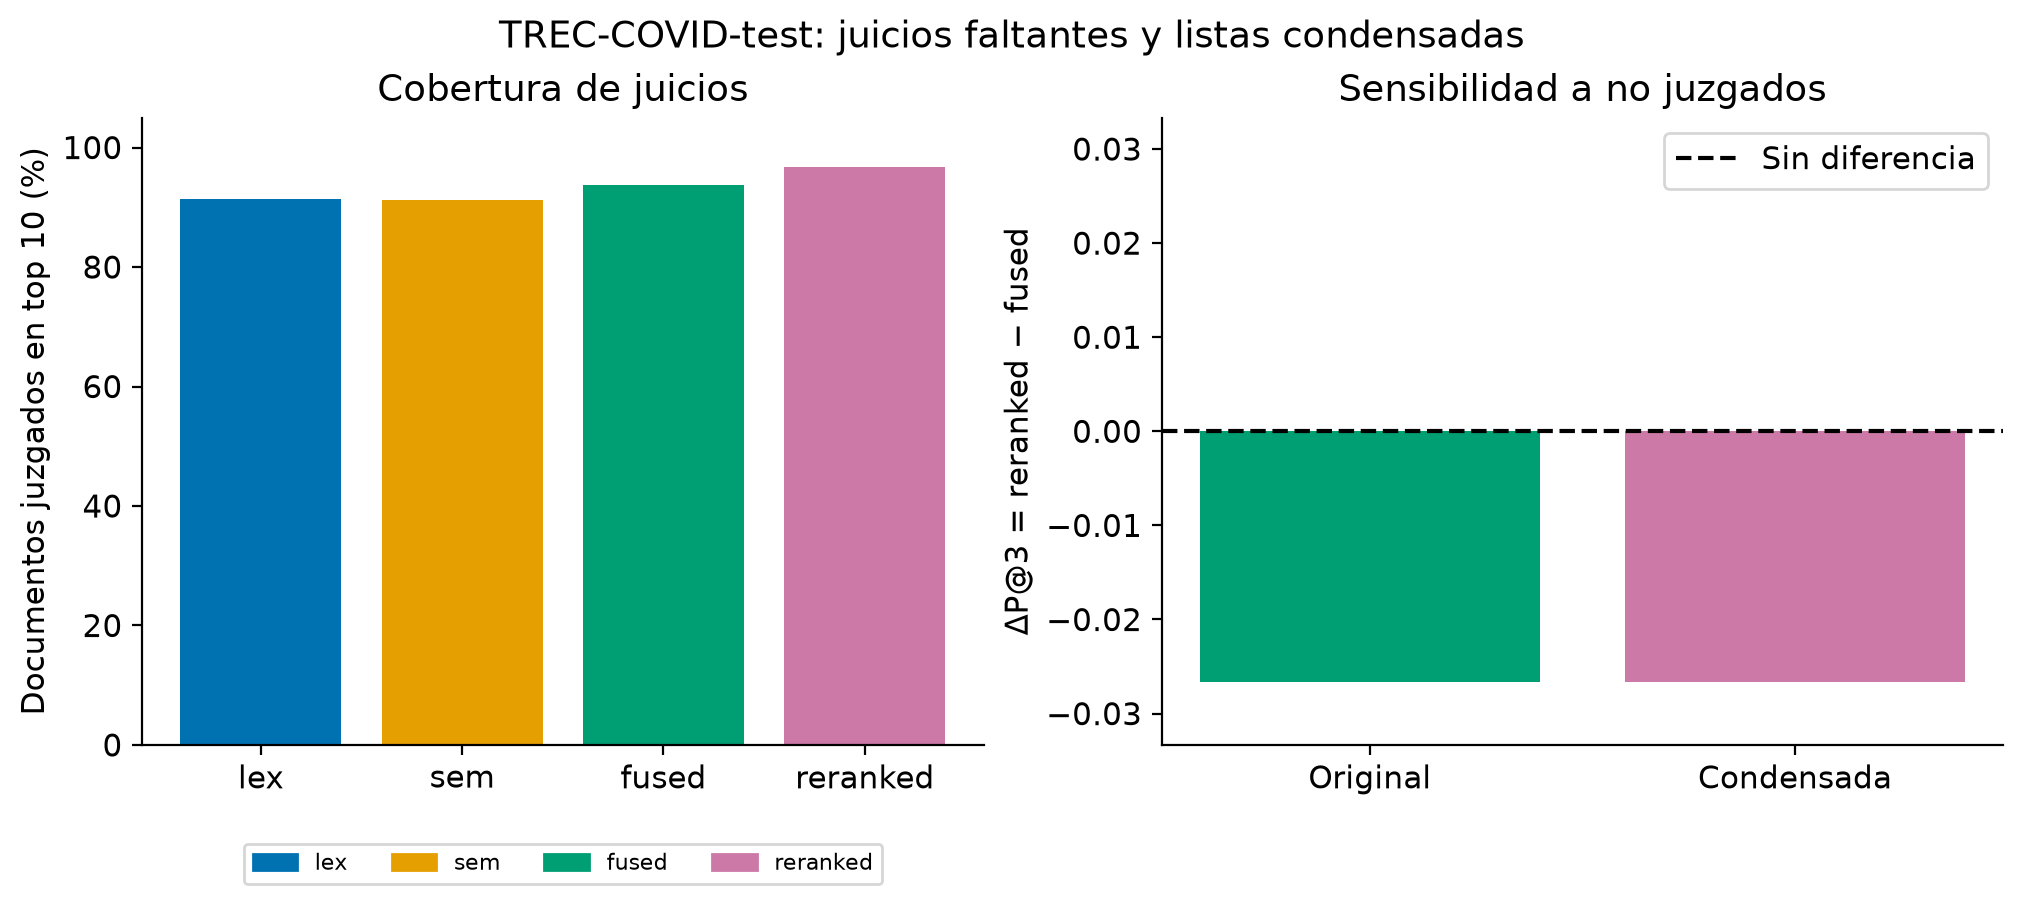

In [26]:
display(Image(filename=str(OUT / 'figs' / 'R8_judged_trec-covid.png')))

Judged@10: fusión 93.8 %, reranker 96.8 %. Los grados 0 cuentan como juzgados.
ΔP@3 condensada = -0.0267; se mantiene el signo respecto de la evaluación original.

## 5. Juicios faltantes y ejemplos

Judged@10 sigue literalmente la presencia del par consulta-documento en los qrels, incluido grado 0. La lista condensada elimina documentos cuyo par no aparece en qrels antes de calcular las métricas. Las dos entradas −1 se conservan y se audita si fueron recuperadas; no se alteran las etiquetas. La condensación de estas listas cortas es un análisis de sensibilidad, no una estimación de relevancia completa. FiQA solo tiene qrels positivos: al condensar se eliminan todos los negativos no juzgados y P@3 queda determinada por el número de relevantes en los mismos candidatos, por lo que la diferencia se fuerza a cero. Esto no demuestra ausencia de sesgo.

In [27]:
display(pd.read_csv(OUT / 'judged.csv'))
display(pd.read_csv(OUT / 'condensed.csv'))
display(Markdown((OUT / 'R9_ejemplos.md').read_text()))

,dataset,route,judged_at_10,judged_at_10_percent
0,fiqa,lex,0.064969,6.496914
1,fiqa,sem,0.112346,11.234568
2,fiqa,fused,0.115895,11.589506
3,fiqa,reranked,0.106327,10.632716
4,trec-covid,lex,0.914000,91.400000
5,trec-covid,sem,0.912000,91.200000
6,trec-covid,fused,0.938000,93.800000
7,trec-covid,reranked,0.968000,96.800000


,dataset,route,precision_at_3,ndcg_at_3
0,fiqa,lex,0.211420,0.362601
1,fiqa,sem,0.352366,0.564852
2,fiqa,fused,0.383745,0.615495
3,fiqa,reranked,0.383745,0.615495
4,trec-covid,lex,0.726667,0.664078
5,trec-covid,sem,0.920000,0.845419
6,trec-covid,fused,0.926667,0.872961
7,trec-covid,reranked,0.900000,0.840000


# R9 — Ejemplos de reranking

Se selecciona una consulta con la mayor mejora y una con la mayor caída de P@3 por dataset.


## FiQA-test — caso de mejora: consulta 2348

Why can't you just have someone invest for you and split the profits (and losses) with him?

ΔP@3 = +0.6667; resultado observado: **mejora**.


| Lista | Posición | ID | Grado | Texto del documento (extracto) |
|---|---:|---|---:|---|
| fused | 1 | 447619 | 1 |  "Why is nobody providing a service that is basically: Give me your money. I will invest it as I see fit. A year later I will return the capital to you, plus half of any profits or losses. This means that if your capital under my management ends up turning a profit, I will keep half of those profits, but if I lose you money, I will cover half those… |
| fused | 2 | 575869 | no juzgado |  "Basically, you either borrow money, or get other people to invest in your business by buying stock or something analogous.  Sometimes you can get people to ""park"" money with you. For example, many people deposit money in a bank checking account. They don't get any interest or other profit from this, they just do it because the bank is a conveni… |
| fused | 3 | 259706 | no juzgado |  "A simple way to ask the question might be to say ""why can't I just use the same trick with my own shares to make money on the way down? Why is borrowing someone else's shares necessary to make the concept a viable one? Why isn't it just the inverse of 'going long'?"" A simple way to think about it is this: to make money by trading something, you… |
| reranked | 1 | 447619 | 1 |  "Why is nobody providing a service that is basically: Give me your money. I will invest it as I see fit. A year later I will return the capital to you, plus half of any profits or losses. This means that if your capital under my management ends up turning a profit, I will keep half of those profits, but if I lose you money, I will cover half those… |
| reranked | 2 | 247486 | 1 |  This means that if your capital under my management ends up turning a profit, I will keep half of those profits, but if I lose you money, I will cover half those losses. The bold part is where you lose me. This absolutely exists with the exception of the loss insurance.  It just requires a lot more than the general retail consumer investor has to … |
| reranked | 3 | 134864 | 1 |  Such an offer has negative value, so it's hard to see how it would make sense to accept it. The offer has two components, one part that you gain and one part that you lose. The gain is that half your losses are covered. The cost is that half your profits are lost. For that to be a net benefit to you, you would have to expect that you will gain mor… |

## FiQA-test — caso de caída: consulta 1393

Which is better when working as a contractor, 1099 or incorporating?

ΔP@3 = -0.6667; resultado observado: **caída**.


| Lista | Posición | ID | Grado | Texto del documento (extracto) |
|---|---:|---|---:|---|
| fused | 1 | 220022 | 1 |  It makes no difference for tax purposes. If you are 1099, you will pay the same amount of taxes as if you formed a corporation and then paid yourself (essentially you are doing this as a 1099 contractor, just not formally). Legally, I don't know the answer.  I would assume you have some legal protections by forming an LLC but practically I think t… |
| fused | 2 | 352640 | 1 |  I am surprised no one has mentioned the two biggest things (in my opinion).  Or I should say, the two biggest things to me.  First, 1099 have to file quarterly self employment taxes.  I do not know for certain but I have heard that often times you will end up paying more this way then even a W-2 employees.  Second, an LLC allows you to deduct busi… |
| fused | 3 | 532932 | 1 |  Unless the amounts involved are very small, it is MUCH better to incorporate. First, incorporation gives you limited liability for your acts as an employee. As an individual, you have unlimited liability. Second, incorporating allows you to deduct (for tax purposes) the costs of doing business, including all of your health insurance, most transpor… |
| reranked | 1 | 234436 | no juzgado |  Another thing to consider, however, is the deductibility of business expenses.  Let's assume that the employer can legitimately hire you as a 1099 contractor.  (Would you be able to telecommute? Would you have a high degree of control over when you worked and when you didn't?  These factors also affect whether you're a true independent 1099 contra… |
| reranked | 2 | 586026 | no juzgado |  Forms 1099 and W2 are mutually exclusive. Employers file both, not the employees. 1099 is filed for contractors, W2 is filed for employees. These terms are defined in the tax code, and you may very well be employee, even though your employer pays you as a contractor and issues 1099. You may complain to the IRS if this is the case, and have them ex… |
| reranked | 3 | 532932 | 1 |  Unless the amounts involved are very small, it is MUCH better to incorporate. First, incorporation gives you limited liability for your acts as an employee. As an individual, you have unlimited liability. Second, incorporating allows you to deduct (for tax purposes) the costs of doing business, including all of your health insurance, most transpor… |

## TREC-COVID-test — caso de mejora: consulta 2

how does the coronavirus respond to changes in the weather

ΔP@3 = +0.3333; resultado observado: **mejora**.


| Lista | Posición | ID | Grado | Texto del documento (extracto) |
|---|---:|---|---:|---|
| fused | 1 | 4bz7xeev | 0 | Substantial Changes in Nitrate Oxide and Ozone after Excluding Meteorological Impacts during the COVID-19 Outbreak in Mainland China [Image: see text] The COVID-19 outbreak in China led to dramatic changes in human activities resulting from the sudden infection prevention and control measures. Here, we use ground-level observations and model simula… |
| fused | 2 | 3svnvozz | 2 | Roles of meteorological conditions in COVID-19 transmission on a worldwide scale The novel coronavirus (SARS-CoV-2/ 2019-nCoV) identified in Wuhan, China, in December 2019 has caused great damage to public health and economy worldwide with over 140,000 infected cases up to date. Previous research has suggested an involvement of meteorological condi… |
| fused | 3 | zespmk29 | 2 | How diseases rise and fall with the seasons—and what it could mean for coronavirus Scientists and doctors have observed for thousands of years that some diseases, such as polio and influenza, rise and fall with the seasons But why? Ongoing research in animals and humans suggests a variety of causes, including changes in the environment (like pH, te… |
| reranked | 1 | w7ycc07b | 2 | Does weather affect the growth rate of COVID-19, a study to comprehend transmission dynamics on human health Abstract The undefendable outbreak of novel coronavirus (SARS-COV-2) lead to a global health emergency due to its higher transmission rate and longer symptomatic duration, created a health surge in a short time. Since Nov 2019 the outbreak i… |
| reranked | 2 | w5kjmw88 | 2 | Weathering the pandemic: How the Caribbean Basin can use viral and environmental patterns to predict, prepare, and respond to COVID-19 The 2020 coronavirus pandemic is developing at different paces throughout the world. Some areas, like the Caribbean Basin, have yet to see the virus strike at full force. When it does, there is reasonable evidence t… |
| reranked | 3 | r1yjphnn | 2 | Does weather affect the growth rate of COVID-19, a study to comprehend transmission dynamics on human health The undefendable outbreak of novel coronavirus (SARS-COV-2) lead to a global health emergency due to its higher transmission rate and longer symptomatic duration, created a health surge in a short time. Since Nov 2019 the outbreak in China, … |

## TREC-COVID-test — caso de caída: consulta 19

what type of hand sanitizer is needed to destroy Covid-19?

ΔP@3 = -0.6667; resultado observado: **caída**.


| Lista | Posición | ID | Grado | Texto del documento (extracto) |
|---|---:|---|---:|---|
| fused | 1 | y777xosr | 2 | Hand Sanitizers: A Review of Ingredients, Mechanisms of Action, Modes of Delivery, and Efficacy Against Coronaviruses BACKGROUND: The emergence of the novel virus, SARS-CoV-2, has posed unprecedented challenges to public health around the world. Currently, strategies to deal with COVID-19 are purely supportive and preventative, aimed at reducing tr… |
| fused | 2 | hma2kvn2 | 1 | COVID-19 and frequent use of hand sanitizers; human health and environmental hazards by exposure pathways Abstract Till date no medication or vaccine is available to cope with the COVID-19 infection and infection rate is increasing drastically across the globe. Only preventive measures and healthy life style with efficient immune system have been s… |
| fused | 3 | eevs62xf | 1 | COVID-19 and frequent use of hand sanitizers; human health and environmental hazards by exposure pathways Till date no medication or vaccine is available to cope with the COVID-19 infection and infection rate is increasing drastically across the globe. Only preventive measures and healthy life style with efficient immune system have been suggested … |
| reranked | 1 | gfyup5aj | 0 | European Task Force on Contact Dermatitis statement on coronavirus 19 disease (COVID-19) outbreak and the risk of adverse cutaneous reactions. Among the basic protective measures against COVID-19, the need to wash hands frequently and in a prolonged way using soap, and to regularly use alcohol-based hand sanitizers is well established for the whole… |
| reranked | 2 | yjg54yyk | 0 | Sanitizer aerosol-driven ocular surface disease (SADOSD)-A COVID-19 repercussion? Since the onset of the COVID-19 pandemic, there has been an advisory for regular and thorough cleaning of hands besides other measures such as social distancing and self-isolation. The rationale for the same is to prevent the transfer of the virus from hands that have… |
| reranked | 3 | eevs62xf | 1 | COVID-19 and frequent use of hand sanitizers; human health and environmental hazards by exposure pathways Till date no medication or vaccine is available to cope with the COVID-19 infection and infection rate is increasing drastically across the globe. Only preventive measures and healthy life style with efficient immune system have been suggested … |

## 6. Tabla para el paper y rutas de respaldo

Si falla el reranker, la ruta de respaldo es fused; si falla la ruta semántica, lex; si falla la ruta léxica, sem. La tabla incluye relevancia, incertidumbre y cobertura de juicios. Estos resultados no miden latencia ni verifican un SLO.

In [28]:
display(pd.read_csv(OUT / 'paper_table.csv').T)
print('Run files:', sorted(p.name for p in (OUT / 'runs').glob('*.trec')))

,0,1
dataset,fiqa,trec-covid
alpha,0.85,0.85
recall_at_20_fused,0.530503,0.033915
n_queries,648,50
resamples,10000,10000
seed,42,42
delta_precision_at_3,-0.020576,-0.026667
ci_95_low,-0.035494,-0.093333
ci_95_high,-0.005658,0.033333
condensed_delta_precision_at_3,0.0,-0.026667


Run files: ['fiqa_fused.trec', 'fiqa_lex.trec', 'fiqa_reranked.trec', 'fiqa_sem.trec', 'trec-covid_fused.trec', 'trec-covid_lex.trec', 'trec-covid_reranked.trec', 'trec-covid_sem.trec']


## 7. Conclusión y limitaciones

- En **fiqa**, el cross-encoder empeora P@3 en promedio: Δ = -0.0206 (-2.06 puntos porcentuales).
- Su IC pareado 95 % [-0.0355, -0.0057] excluye cero; la Δ condensada es +0.0000 y el signo cambia. El empate condensado es estructural porque FiQA solo contiene juicios positivos.
- En **trec-covid**, el cross-encoder empeora P@3 en promedio: Δ = -0.0267 (-2.67 puntos porcentuales).
- Su IC pareado 95 % [-0.0933, +0.0333] incluye cero; la Δ condensada es -0.0267 y el signo se mantiene.
- Se aplicó el mismo α=0,85 a ambos tests, sin selección de hiperparámetros sobre prueba.
- El reranker únicamente reordena: no puede rescatar relevantes ausentes de la unión de candidatos.
- Los juicios incompletos, los textos truncados a 512 tokens y la transferencia del modelo a dominios distintos limitan la interpretación.
- El resultado es una evaluación de relevancia offline; no demuestra una mejora bajo un presupuesto de latencia.

## 8. Procedencia y archivos

Se adjuntan el script de evaluación, el generador de figuras, los runs TREC, los puntajes parquet, los datos por consulta, las muestras bootstrap y la contabilidad Slurm. El α validado se copia byte por byte; la curva de desarrollo solo se visualiza.

In [29]:
print('α SHA-256:', sha(OUT / 'alpha_usado.json'))
print('Candidatos SHA-256:')
for ds in ['fiqa','trec-covid']:
    print(ds, sha(OUT / f'cands_{ds}_test.parquet'))
assert len(list((OUT / 'figs').glob('*.png'))) == 15
assert len(pd.read_csv(OUT / 'bootstrap.csv')) == 2
print('Verificación del notebook completada.')

α SHA-256: 10f8b9ed90d17367837e9f40f7fd3a21c0e6b2db07b6f91c6892b3bf1560d500
Candidatos SHA-256:
fiqa e09d73e5c0b5618e1f53abead381a71264f5bbe02f0a4d4a35811f048d18ace3
trec-covid 9d550c7ddcf5382a65b5c800a5c8766276aef9d43d8d28e40fa74209ff89c4a9
Verificación del notebook completada.
